# Group Project Cryosphere

Earth Observation group project about a glacier in the Himalaya in Nepal. We try to measure glacier area, surface temperature variation, and wet/total snow area using satellite data from Google Earth Engine. We investigate these aspects on the time series of 2015 - 2026.

## Initializing

In [1]:
# run once at beginning, supply token
import ee
ee.Authenticate()

True

In [2]:
cloud_project = 'my-hello-world-508910' # replace with your own project id
ee.Initialize(project=cloud_project)

In [3]:
import time
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
AOI = ee.Geometry.Polygon([[81.757507, 30.201033], [81.756821, 30.220912], [81.759224, 30.242269], [81.764717, 30.255022], [81.779823, 30.248794], [81.789093, 30.230701], [81.79184, 30.20222], [81.78669, 30.187383], [81.766777, 30.184416], [81.757507, 30.201033]]) # from WhatsApp chat
aoi_center_lon_lat = AOI.centroid().coordinates().getInfo() # lon/lat
print(aoi_center_lon_lat)

[81.77351981643268, 30.21758428472345]


## Image Collections Analysis

Get a sense of how many Images we are working with, from what date they are and how much they are covered by clouds.

In [5]:
s2_toa = ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Top of Atmosphere")
s2_boa = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Bottom of Atmosphere")

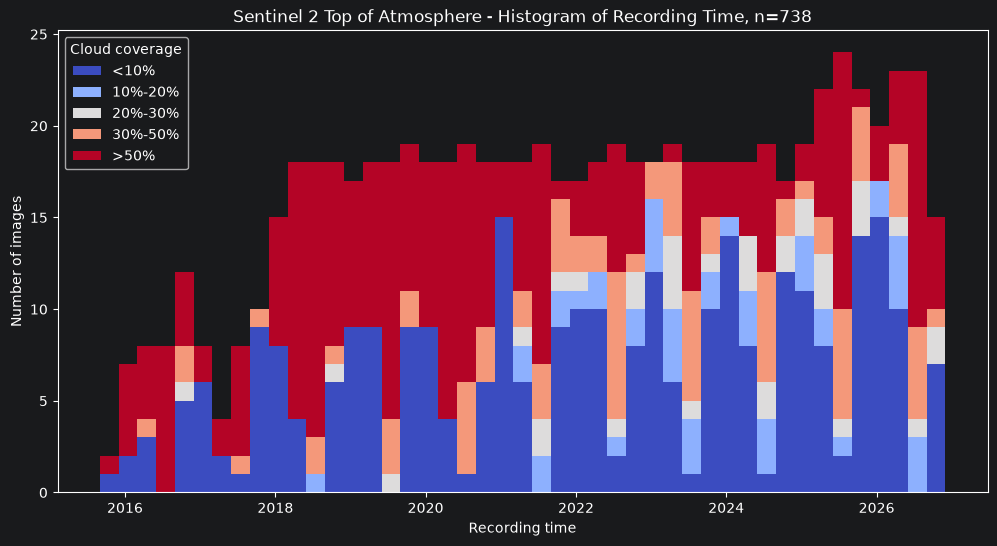

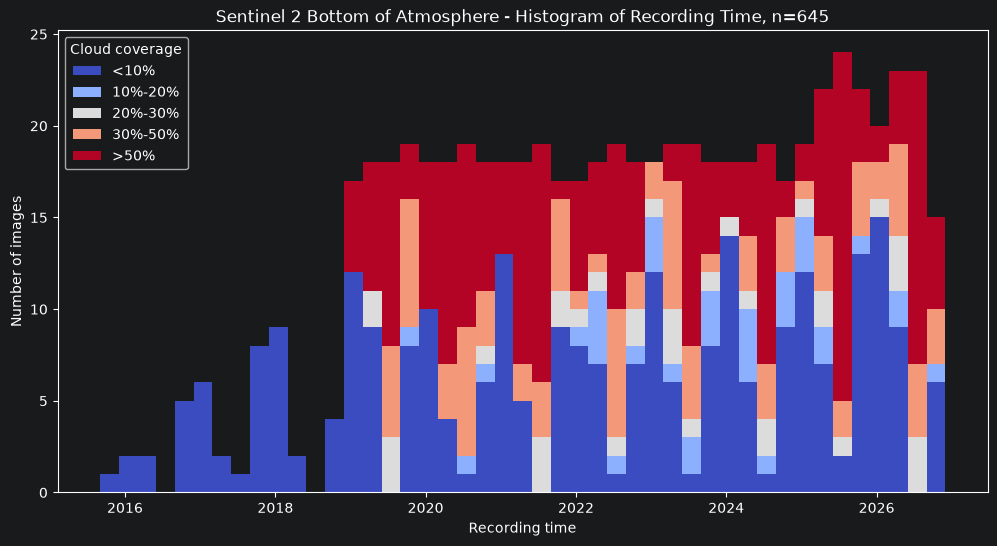

In [6]:
def plot_histogram_image_collection(
        collection: ee.ImageCollection,
        start: str,
        end: str,
        split_percent: list[int | float] | None = None,
        color_space: str = "coolwarm"
) -> None:
    """Plots the image collection times of recording with color according to Cloudy Pixel Percentage. Bins are quarter yearly, please use start and end dates that align with 3-month cycles.
    :param collection: ee.ImageCollection
    :param start: Date 'yyyy-MM-dd'
    :param end: Date 'yyyy-MM-dd'
    :param split_percent: list of percentiles where colors are split. Numbers must be between 0 and 100.
    :param color_space: matplotlib.pyplot color space name, such as 'coolwarm'.
    :return: None
    """

    if split_percent is None or len(split_percent) == 0:
        split_percent = [10, 20, 30, 50]

    times = collection.aggregate_array('system:time_start').getInfo()
    clouds = collection.aggregate_array('CLOUDY_PIXEL_PERCENTAGE').getInfo()
    dates = pd.to_datetime(times, unit='ms')

    cloud_bins = [0, *split_percent, 100]
    cloud_labels = [
        f"<{split_percent[0]}%",
        *[f"{split_percent[n]}%-{split_percent[n+1]}%" for n in range(len(split_percent)-1)],
        f">{split_percent[-1]}%"
    ]
    cloud_categories = pd.cut(clouds, bins=cloud_bins, labels=cloud_labels, include_lowest=True)

    plt.figure(figsize=(12, 6))

    data = [dates[cloud_categories == category] for category in cloud_labels]
    date_bins = pd.date_range(start=start, end=end, freq='3MS')

    colors = plt.get_cmap(color_space)(np.linspace(0, 1, len(cloud_labels)))

    plt.hist(data, bins=date_bins, stacked=True, label=cloud_labels, color=colors)

    plt.xlabel("Recording time")
    plt.ylabel("Number of images")
    plt.title(f"{collection.get('collection_name').getInfo()} - Histogram of Recording Time, n={collection.size().getInfo()}")
    plt.legend(title="Cloud coverage")
    plt.show()


plot_histogram_image_collection(s2_toa, "2015-09-01", "2027-01-01")
plot_histogram_image_collection(s2_boa, "2015-09-01", "2027-01-01")

In these Histograms we see that there Sentinel 2 provides data with few clouds from 2016 to 2026. Also, we see that cloud cover is very seasonal. Especially in summer, images with cloud coverage <30% are scarce. Although more and more images are provided throughout the time period, image count has been very consistent since 2019.

## Glacier area

Description here...

## Surface temperature variation

Description here...

## Wet/total snow area

Description here...